# Gradient Boosting Classification (Owner: Sriniket Deeduvanu)

### Objective

Gradient Boosting builds an ensemble of decision trees sequentially, with each new tree improving on errors made by the existing ensemble. This notebook uses `HistGradientBoostingClassifier`, a histogram-based implementation of gradient boosting.

### Hyperparameter Tuning

We evaluated six configurations by varying the learning rate (`learning_rate`), number of boosting iterations (`max_iter`), and maximum number of leaves per tree (`max_leaf_nodes`). Early stopping was enabled to help prevent unnecessary training. All configurations used the same train-validation split and `random_state=42`.

### Results and Model Selection

The best configuration was:

* `learning_rate = 0.1`
* `max_iter = 250`
* `max_leaf_nodes = 31`
* `l2_regularization = 1.0`

It achieved a validation micro-F1 of **0.7343 (73.43%)** and macro-F1 of **0.6764**. Increasing the number of iterations from 150 to 250 improved validation micro-F1 from 0.7277 to 0.7343. The model used all 250 iterations, so early stopping did not terminate training early for this configuration.

### Interpretation

The model performs best on damage grade 2, with an F1-score of 0.79 and recall of 0.85. Grade 1 has an F1-score of 0.57 and recall of 0.49, while grade 3 has an F1-score of 0.67 and recall of 0.61. This indicates that the model identifies grade 2 more effectively than the other grades.

The training micro-F1 (0.7523) is slightly higher than validation micro-F1 (0.7343), indicating a modest generalization gap. Among the six tested configurations, the selected model achieved the highest validation micro-F1.


In [1]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


Training: Baseline
Training: Lower learning rate
Training: More iterations
Training: Fewer leaves
Training: Higher learning rate
Training: Combined tuning


,configuration,learning_rate,max_iter,max_leaf_nodes,actual_iterations,train_micro_f1,val_micro_f1,val_macro_f1,val_accuracy
2,More iterations,0.10,250,31,250,0.752326,0.734330,0.676391,0.734330
4,Higher learning rate,0.15,150,31,150,0.748950,0.730895,0.671670,0.730895
0,Baseline,0.10,150,31,150,0.737620,0.727691,0.666612,0.727691
1,Lower learning rate,0.05,150,31,150,0.719781,0.716122,0.648327,0.716122
3,Fewer leaves,0.10,150,15,150,0.719407,0.716026,0.649058,0.716026
5,Combined tuning,0.05,250,15,250,0.712155,0.709656,0.641268,0.709656


Selected configuration: {'name': 'More iterations', 'learning_rate': 0.1, 'max_iter': 250, 'max_leaf_nodes': 31}
Best validation micro-F1: 0.7343
gradient_boosting: micro-F1 = 0.7343
              precision    recall  f1-score   support

           1       0.69      0.49      0.57      5025
           2       0.73      0.85      0.79     29652
           3       0.76      0.61      0.67     17444

    accuracy                           0.73     52121
   macro avg       0.72      0.65      0.68     52121
weighted avg       0.73      0.73      0.73     52121



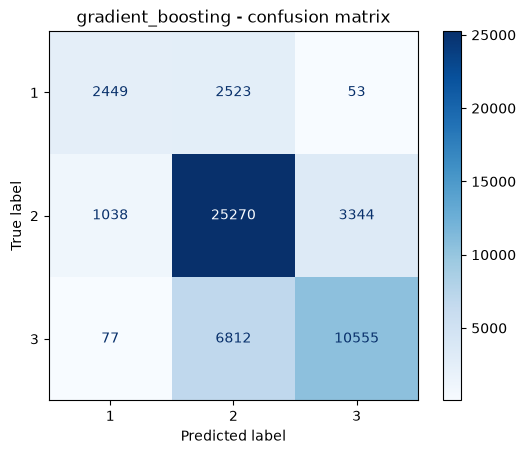

Validation accuracy: 0.7343
Macro F1-score: 0.6764
Training score: 0.7523
Validation score: 0.7343
Iterations used after early stopping: 250


In [2]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Test a small set of hyperparameter configurations
configs = [
    {"name": "Baseline", "learning_rate": 0.1, "max_iter": 150, "max_leaf_nodes": 31},
    {"name": "Lower learning rate", "learning_rate": 0.05, "max_iter": 150, "max_leaf_nodes": 31},
    {"name": "More iterations", "learning_rate": 0.1, "max_iter": 250, "max_leaf_nodes": 31},
    {"name": "Fewer leaves", "learning_rate": 0.1, "max_iter": 150, "max_leaf_nodes": 15},
    {"name": "Higher learning rate", "learning_rate": 0.15, "max_iter": 150, "max_leaf_nodes": 31},
    {"name": "Combined tuning", "learning_rate": 0.05, "max_iter": 250, "max_leaf_nodes": 15},
]

results = []
best_model = None
best_config = None
best_f1 = -1

for config in configs:
    print(f"Training: {config['name']}")

    model = Pipeline([
        ("preprocessor", build_tree_preprocessor(X_train)),
        ("classifier", HistGradientBoostingClassifier(
            learning_rate=config["learning_rate"],
            max_iter=config["max_iter"],
            max_leaf_nodes=config["max_leaf_nodes"],
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_f1 = f1_score(y_train, train_pred, average="micro")
    val_f1 = f1_score(y_val, val_pred, average="micro")

    results.append({
        "configuration": config["name"],
        "learning_rate": config["learning_rate"],
        "max_iter": config["max_iter"],
        "max_leaf_nodes": config["max_leaf_nodes"],
        "actual_iterations": model.named_steps["classifier"].n_iter_,
        "train_micro_f1": train_f1,
        "val_micro_f1": val_f1,
        "val_macro_f1": f1_score(y_val, val_pred, average="macro"),
        "val_accuracy": accuracy_score(y_val, val_pred)
    })

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_model = model
        best_config = config

results_df = pd.DataFrame(results).sort_values(
    "val_micro_f1", ascending=False
)
display(results_df)

print("Selected configuration:", best_config)
print(f"Best validation micro-F1: {best_f1:.4f}")

# Evaluate the selected model
y_val_pred_gb = best_model.predict(X_val)

gb_f1 = evaluate_model(
    "gradient_boosting",
    y_val,
    y_val_pred_gb
)

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred_gb):.4f}")
print(f"Macro F1-score: {f1_score(y_val, y_val_pred_gb, average='macro'):.4f}")
print(f"Training score: {best_model.score(X_train, y_train):.4f}")
print(f"Validation score: {best_model.score(X_val, y_val):.4f}")
print(
    "Iterations used after early stopping:",
    best_model.named_steps["classifier"].n_iter_
)